[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dilrabonu/ai-linguistics-uz/blob/main/notebooks/04_tokenization_audit.ipynb)

# 4-§. Tokenizatsiya va morfologiya: oʻzbek tili soligʻi
### Chapter 4. Tokenization and morphology: the Uzbek tokenizer tax

**Summary.** We measure how many tokens popular tokenizers spend on the same content in Uzbek and English (fertility, parity on FLORES-200).
We then train our own BPE tokenizers on Uzbek Wikipedia and check how well token boundaries match morpheme boundaries.
Runs on a free Colab CPU in about 10–15 minutes; no GPU and no model weights needed.

**Bu daftarchada nima qilamiz.** 4-§ dagi amaliy mashgʻulotning 5 qadamini bajaramiz: parallel matnni yuklaymiz, tokenizatorlarni solishtiramiz, „oʻzbek tili soligʻi“ni oʻlchaymiz, oʻz tokenizatorimizni oʻqitamiz va token chegaralarini morfema chegaralari bilan taqqoslaymiz. Barcha hisob-kitob `src/uzling/` kutubxonasida; daftarcha faqat funksiyalarni chaqiradi.

*English note: the notebook follows the 5 practical steps of §4. All logic lives in `src/uzling/` (mainly `tokenizer_stats.py` and `ch04.py`); cells only call functions. Downloads and trained tokenizers are cached in `data/cache/`, so a second run is fast.*

| Qadam | Mazmun | Taxminiy vaqt (Colab CPU, birinchi ishga tushirish) |
|---|---|---|
| 0 | Sozlash | ~1 daqiqa |
| 1 | FLORES-200 ni yuklash | ~15 soniya |
| 2 | Tokenizatorlar | ~1 daqiqa |
| 3 | Fertility va parity auditi | ~1 daqiqa |
| 4 | Oʻz BPE tokenizatorimiz | ~5–8 daqiqa |
| 5 | Morfologik moslik | < 10 soniya |
| 6 | Xulosa va rasmlar | ~30 soniya |

## 0. Sozlash (≈ 1 daqiqa)
Colabʼda repozitoriy klonlanadi va `uzling` paketi oʻrnatiladi. Kompyuteringizda ishga tushirsangiz, repozitoriy papkasi avtomatik topiladi.

*English note: in Colab this clones the repo and installs the pinned libraries from `requirements-colab.txt`; locally it finds the repo root. `src/` is also added to `sys.path`, so the notebook works even without `pip install -e .`.*

In [1]:
import os
import subprocess
import sys
import time
import warnings
from pathlib import Path

T_START = time.time()
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets
REPO_URL = "https://github.com/dilrabonu/ai-linguistics-uz"
if "google.colab" in sys.modules and Path.cwd().name != "ai-linguistics-uz":
    if not Path("ai-linguistics-uz").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL], check=True)
    os.chdir("ai-linguistics-uz")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "-r", "requirements-colab.txt", "-e", "."], check=True)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))  # fallback if `pip install -e .` was not run
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")

import uzling
from uzling import ch04
from uzling.normalize import apostrophe_profile, normalize_uz

timer = ch04.StepTimer(t0=T_START)
timer.steps["0 setup"] = time.time() - T_START
print("uzling", uzling.__version__, "| repo folder:", ROOT.name)

uzling 0.1.0 | repo folder: ai-linguistics-uz


**Parametrlar.** Vaqtingiz kam boʻlsa, `N_WIKI_ARTICLES` ni kamaytiring (masalan, 10 000).

*English note: all tunable sizes are here. Seeds are fixed for the FLORES sample and the bootstrap.*

In [2]:
N_SENTENCES = 1000           # FLORES-200 parallel sentence pairs (from dev + devtest)
N_WIKI_ARTICLES = 40_000     # Uzbek Wikipedia articles for training our BPE
BPE_VOCAB_SIZES = (8_000, 16_000, 32_000)
TRAIN_BALANCED_UZ_EN = True  # also train a 32k uz+en tokenizer (needs English Wikipedia)
N_BOOT = 1000                # bootstrap resamples for the 95% CIs
CONTEXT_WINDOW = 4096        # tokens
SEED = ch04.SEED             # 42

import random

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
ch04.setup_style()

## 1-qadam. FLORES-200 dan oʻzbekcha va inglizcha 1 000 ta jumla (≈ 15 soniya)
FLORES-200 — 200 tilga professional tarjima qilingan bir xil jumlalar toʻplami. Har bir oʻzbekcha jumlaning inglizcha tarjimasi bor, shuning uchun tokenlar sonini *bir xil mazmun* uchun solishtira olamiz. Oʻzbekcha matnni `normalize_uz` bilan normallashtiramiz (oʻ/gʻ uchun ʻ, tutuq belgisi uchun ʼ), lekin xom variantni ham saqlaymiz (3-qadam).

*English note: we use the official FLORES-200 archive (CC BY-SA 4.0, no login needed) and sample 1,000 sentence indices with a fixed seed from dev (997) + devtest (1,012). The same indices are used for both languages. Uzbek is normalized; the raw text is kept for the raw-vs-normalized experiment.*

In [3]:
timer.start("1 data")
flores = ch04.load_flores(("uzn_Latn", "eng_Latn"), n=N_SENTENCES, seed=SEED)
uz_raw = flores["sentences"]["uzn_Latn"]
en = flores["sentences"]["eng_Latn"]
uz = [normalize_uz(s) for s in uz_raw]
meta = {k: v for k, v in flores["meta"].items() if k != "indices"}
print(meta)
print("Apostrophes in raw Uzbek:", apostrophe_profile("".join(uz_raw)))
print("Apostrophes after normalization:", apostrophe_profile("".join(uz)))
for i in (0, 1, 2):
    print(f"\n[{i + 1}] UZ: {uz[i]}\n    EN: {en[i]}")
timer.stop()

{'source': 'https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz', 'pool': 2009, 'n': 1000, 'from_dev': 516, 'from_devtest': 484, 'seed': 42}
Apostrophes in raw Uzbek: {'U+0027': 2276, 'U+02BC': 1, 'U+02BB': 10}
Apostrophes after normalization: {'U+02BC': 213, 'U+02BB': 2073, 'U+0027': 1}

[1] UZ: Dushanba kuni Stenford Universitetining Tibbiyot maktabi olimlari hujayralarni turlariga qarab saralay oladigan yangi tashxis vositasi ixtirosini eʼlon qildi: har biri taxminan bir AQSH senti atrofida boʻlgan standart rangli printerlardan foydalangan holda ishlab chiqarish mumkin boʻlgan ingichka bosma chip.
    EN: On Monday, scientists from the Stanford University School of Medicine announced the invention of a new diagnostic tool that can sort cells by type: a tiny printable chip that can be manufactured using standard inkjet printers for possibly about one U.S. cent each.

[2] UZ: Yetakchi tadqiqotchilarning aytishicha, bu kam daromadli davlatlarda bemorlarning saraton, sil, OIV v

## 2-qadam. Tokenizatorlarni yuklash (≈ 1 daqiqa)
Beshta ochiq tokenizator: **GPT-2** (inglizcha markazli), **Qwen2.5**, **XLM-R**, **mT5** (koʻp tilli) va **ByT5** (bayt darajasidagi; har bir bayt — bitta token). Llama 3 va Gemma tokenizatorlari yopiq (gated): ular faqat `HF_TOKEN` boʻlsa ishlatiladi. Bizga faqat tokenizatorlar kerak, model ogʻirliklari yuklanmaydi.

*English note: only tokenizer files are downloaded. Gated tokenizers (Llama 3.2, Gemma 3) are used only if an `HF_TOKEN` is set (environment variable or Colab secret) and the licence was accepted on Hugging Face; otherwise they are skipped with a message. Tokens are always counted with `add_special_tokens=False`.*

In [4]:
timer.start("2 tokenizers")
adapters, tok_info = ch04.load_tokenizers()
display(pd.DataFrame(tok_info).T)
for name, info in tok_info.items():
    if info["status"] != "loaded":
        print(f"NOTE: {name} ({info['id']}) {info['status']} -- continuing without it.")
timer.stop()

,id,kind,status,vocab_size,scheme
GPT-2,gpt2,pretrained,loaded,50257,bytelevel
Qwen2.5,Qwen/Qwen2.5-0.5B,pretrained,loaded,151665,bytelevel
XLM-R,xlm-roberta-base,pretrained,loaded,250002,sentencepiece
mT5,google/mt5-small,pretrained,loaded,250100,sentencepiece
ByT5,google/byt5-small,pretrained,loaded,384,bytes
Llama 3.2,meta-llama/Llama-3.2-1B,gated,skipped: no HF_TOKEN,NaN,NaN
Gemma 3,google/gemma-3-1b-pt,gated,skipped: no HF_TOKEN,NaN,NaN


NOTE: Llama 3.2 (meta-llama/Llama-3.2-1B) skipped: no HF_TOKEN -- continuing without it.
NOTE: Gemma 3 (google/gemma-3-1b-pt) skipped: no HF_TOKEN -- continuing without it.


**Jumla va soʻz qanday boʻlinadi?** `|` belgisi token chegarasini koʻrsatadi. `⟨CA⟩⟨BB⟩` — ʻ belgisining UTF-8 dagi ikki bayti alohida tokenlarga ajralganini bildiradi.

*English note: the same sentence and word split by each tokenizer. The coloured version of this view becomes a book figure in step 6.*

In [5]:
from uzling.tokenizer_stats import _readable

for name, ad in adapters.items():
    sent = "|".join(_readable(p) for p in ad.token_bytes(ch04.EXAMPLE_SENTENCE))
    word = "|".join(ad.word_pieces(ch04.EXAMPLE_WORD))
    print(f"{name:8s} {len(ad.token_bytes(ch04.EXAMPLE_SENTENCE)):3d} tokens  {sent}")
    print(f"{'':8s} {ad.n_word_tokens(ch04.EXAMPLE_WORD):3d} tokens  {word}\n")

GPT-2     17 tokens  O|⟨CA⟩|⟨BB⟩|zbek|iston|ning| p|oy|ta|xt|i| Tosh|k|ent| sh|ah|ri
           6 tokens  kit|ob|lar|im|iz|dan

Qwen2.5   16 tokens  O|ʻ|zbek|iston|ning| p|oy|tax|ti| T|osh|k|ent| sh|ah|ri
           6 tokens  kit|ob|lar|im|iz|dan

XLM-R      8 tokens   O|ʻ|zbekiston|ning| poytaxt|i| Toshkent| shahri
           3 tokens  kitob|larimiz|dan

mT5       12 tokens   O|ʻ|zbekiston|ning| poy|taxt|i| |Toshkent| |shahr|i
           4 tokens  kito|b|larimiz|dan

ByT5      41 tokens  O|⟨CA⟩|⟨BB⟩|z|b|e|k|i|s|t|o|n|n|i|n|g| |p|o|y|t|a|x|t|i| |T|o|s|h|k|e|n|t| |s|h|a|h|r|i
          15 tokens  k|i|t|o|b|l|a|r|i|m|i|z|d|a|n



## 3-qadam. Fertility va parity auditi (≈ 1 daqiqa)
* **Soʻz** — boʻshliq boʻyicha ajratilgan, chetidagi tinish belgilari olib tashlangan birlik (ʻ va ʼ harf hisoblanadi).
* **Fertillik** = tokenlar soni / soʻzlar soni. **Parity** = oʻzbekcha tokenlar / shu matnning inglizcha tarjimasi tokenlari (Petrov va boshq., 2023).
* **Davomli soʻzlar ulushi** — bir nechta tokenga boʻlingan soʻzlar ulushi; **kontekst sigʻimi** — 4 096 tokenli oynaga sigʻadigan soʻzlar soni.

*English note: definitions are in `uzling.tokenizer_stats`. Parity is reported at corpus level (ratio of token sums; primary) with a bootstrap 95% CI, and as the median of sentence-level ratios with its own bootstrap CI (1,000 resamples, seed 42).*

,tokenizer,vocab_size,fertility_uz,fertility_en,parity,parity_ci_low,parity_ci_high,parity_median,continued_word_rate_uz,continued_word_rate_en,context_words_uz_4096,context_words_en_4096
0,GPT-2,50257,3.561,1.232,2.381,2.351,2.408,2.385,0.899,0.069,1150.171,3323.389
1,Qwen2.5,151665,3.289,1.257,2.156,2.129,2.179,2.161,0.892,0.077,1245.460,3258.210
2,XLM-R,250002,2.248,1.395,1.328,1.314,1.340,1.320,0.623,0.202,1821.744,2935.698
3,mT5,250100,2.553,1.532,1.373,1.358,1.386,1.365,0.769,0.189,1604.342,2673.753
4,ByT5,384,8.334,6.006,1.144,1.134,1.152,1.136,0.993,0.977,491.483,681.985


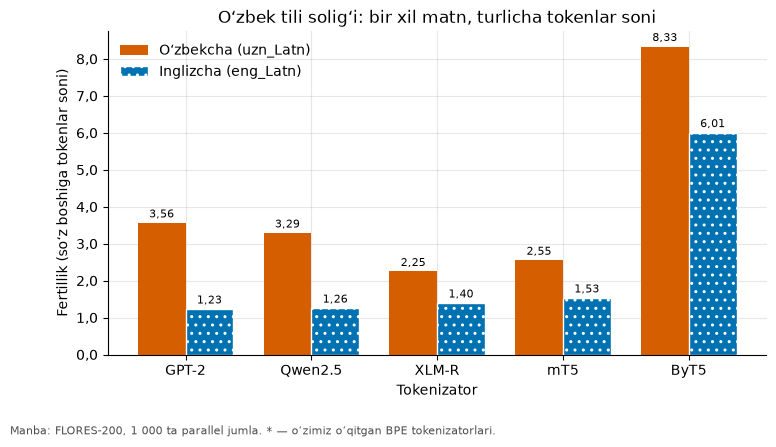

In [6]:
timer.start("3 audit")
kinds = {n: info["kind"] for n, info in tok_info.items()}
table_pre, counts_pre = ch04.audit(adapters, uz, en, kinds=kinds, n_boot=N_BOOT,
                                   window=CONTEXT_WINDOW)
cols = ["tokenizer", "vocab_size", "fertility_uz", "fertility_en", "parity", "parity_ci_low",
        "parity_ci_high", "parity_median", "continued_word_rate_uz", "continued_word_rate_en",
        f"context_words_uz_{CONTEXT_WINDOW}", f"context_words_en_{CONTEXT_WINDOW}"]
display(table_pre[cols])
fig = ch04.plot_fertility(table_pre)

**Qoʻshimcha tajriba: xom va normallashtirilgan matn.** FLORES dagi oʻzbekcha matnda deyarli barcha apostroflar oddiy ASCII `'` belgisi. Uni ʻ / ʼ ga almashtirsak, tokenlar soni oʻzgaradimi? (2-§ bilan bogʻliq.)

*English note: same sentences, same English reference; only the apostrophe characters differ. ASCII `'` is 1 byte in UTF-8, ʻ and ʼ are 2 bytes each.*

In [7]:
rvn_pre = ch04.raw_vs_normalized(adapters, uz_raw, uz, en)
display(rvn_pre)
timer.stop()

,tokenizer,tokens_raw,tokens_normalized,change_pct,fertility_raw,fertility_normalized,parity_raw,parity_normalized,sentences_changed
0,GPT-2,59676,62136,4.122,3.420,3.561,2.287,2.381,872
1,Qwen2.5,56837,57382,0.959,3.258,3.289,2.135,2.156,394
2,XLM-R,39229,39230,0.003,2.248,2.248,1.328,1.328,1
3,mT5,44545,44546,0.002,2.553,2.553,1.373,1.373,1
4,ByT5,143136,145411,1.589,8.204,8.334,1.126,1.144,872


## 4-qadam. Oʻzbek Vikipediyasida oʻz BPE tokenizatorimizni oʻqitamiz (≈ 5–8 daqiqa)
HF `tokenizers` kutubxonasi bilan bayt darajasidagi BPE (GPT-2 va Llama 3 kabi) 8 000, 16 000 va 32 000 lugʻat hajmida oʻqitiladi. Faqat oʻzbekcha matnda oʻqitilgan tokenizator uchun inglizcha parity maʼnosiz: u inglizchani bilmaydi. Shuning uchun teng hajmdagi oʻzbekcha + inglizcha matnda ham 32 000 lik tokenizator oʻqitamiz va uning parityʼsini koʻramiz.

*English note: Wikipedia is streamed (`wikimedia/wikipedia`, config `20231101.uz`, the only Uzbek dump on the Hub), normalized, and articles that are less than 90% Latin script are dropped. Caveat: a monolingual tokenizer has no meaningful English parity; the balanced uz+en tokenizer (English Wikipedia sample with the same number of characters) is the fair comparison.*

In [8]:
timer.start("4a wikipedia")
wiki_uz, wiki_uz_meta = ch04.load_wiki_uz(N_WIKI_ARTICLES)
print(wiki_uz_meta)
if TRAIN_BALANCED_UZ_EN:
    wiki_en, wiki_en_meta = ch04.load_wiki_en(char_budget=wiki_uz_meta["characters"])
    print(wiki_en_meta)
timer.start("4b train BPE")
own = {}
for v in BPE_VOCAB_SIZES:
    own[f"BPE-uz-{v // 1000}k"] = ch04.train_bpe(wiki_uz, v, f"bpe_uz_{v}_{N_WIKI_ARTICLES}")
if TRAIN_BALANCED_UZ_EN:
    v = max(BPE_VOCAB_SIZES)
    own[f"BPE-uz+en-{v // 1000}k"] = ch04.train_bpe(
        wiki_uz + wiki_en, v, f"bpe_uzen_{v}_{N_WIKI_ARTICLES}")
timer.start("4c audit own")
table_own, counts_own = ch04.audit(own, uz, en, kinds={n: "own" for n in own}, n_boot=N_BOOT,
                                   window=CONTEXT_WINDOW)
table_own["parity_meaningful"] = ~table_own.tokenizer.str.startswith("BPE-uz-")
display(table_own[["tokenizer", "vocab_size", "fertility_uz", "fertility_en", "parity",
                   "parity_ci_low", "parity_ci_high", "continued_word_rate_uz",
                   "parity_meaningful"]])
rvn_own = ch04.raw_vs_normalized(own, uz_raw, uz, en)
timer.stop()

{'dataset': 'wikimedia/wikipedia', 'config': '20231101.uz', 'articles_read': 40000, 'articles_kept': 38912, 'articles_dropped': 1088, 'characters': 26106660, 'min_latin_share': 0.9}


{'dataset': 'wikimedia/wikipedia', 'config': '20231101.en', 'articles_read': 1210, 'articles_kept': 1210, 'articles_dropped': 0, 'characters': 26117032}


,tokenizer,vocab_size,fertility_uz,fertility_en,parity,parity_ci_low,parity_ci_high,continued_word_rate_uz,parity_meaningful
0,BPE-uz-8k,8000,2.023,2.582,0.646,0.639,0.653,0.496,False
1,BPE-uz-16k,16000,1.779,2.376,0.617,0.610,0.623,0.387,False
2,BPE-uz-32k,32000,1.585,2.184,0.598,0.592,0.604,0.286,False
3,BPE-uz+en-32k,32000,1.745,1.350,1.065,1.054,1.075,0.380,True


## 5-qadam. Token va morfema chegaralari (< 10 soniya)
`data/samples/morph_gold_uz.tsv` faylida 100 ta soʻz qoʻlda morfemalarga ajratilgan (masalan, `kitob+lar+imiz+dan`). Har bir tokenizator uchun token chegaralarining **aniqligi** (precision), **toʻliqligi** (recall) va **F1** hisoblanadi.

> ⚠️ Oltin toʻplam hozircha **QORALAMA**: tilshunos tomonidan tekshirilishi kerak. Natijalar dastlabki.

*English note: each word is tokenized as `" " + word` (its form inside a sentence) and boundaries are compared as byte offsets. A boundary inside the 2-byte ʻ character counts as a false boundary. The gold file is a DRAFT awaiting linguist verification.*

In [9]:
timer.start("5 morphology")
gold = ch04.load_morph_gold()
print(len(gold), "gold words;", pd.Series([g["category"] for g in gold]).value_counts().to_dict())
all_adapters = {**adapters, **own}
morph, morph_cat, morph_ex = ch04.morph_scores(all_adapters, gold)
display(morph)
display(morph_ex.pivot(index="tokenizer", columns="word", values="split")
        .loc[list(all_adapters), ch04.SHOWCASE_WORDS])
timer.stop()

100 gold words; {'verb': 31, 'noun': 29, 'tricky': 19, 'deriv': 12, 'mono': 9}


,tokenizer,precision,recall,f1,tp,fp,fn,exact_match,tokens_per_word
0,GPT-2,0.222,0.478,0.303,76,266,83,0.03,4.42
1,Qwen2.5,0.270,0.484,0.347,77,208,82,0.08,3.85
2,XLM-R,0.497,0.491,0.494,78,79,81,0.23,2.57
3,mT5,0.488,0.509,0.498,81,85,78,0.26,2.66
4,ByT5,0.201,1.000,0.335,159,631,0,0.00,8.90
5,BPE-uz-8k,0.545,0.453,0.495,72,60,87,0.18,2.32
6,BPE-uz-16k,0.556,0.346,0.426,55,44,104,0.17,1.99
7,BPE-uz-32k,0.527,0.245,0.335,39,35,120,0.16,1.74
8,BPE-uz+en-32k,0.544,0.352,0.427,56,47,103,0.17,2.03


word,kitoblarimizdan,bolalar,dollar,yuragimda,oʻqituvchilarimizga
tokenizer,,,,,
GPT-2,kit|ob|lar|im|iz|dan,bol|al|ar,dollar,y|ur|ag|im|da,o|⟨CA⟩|⟨BB⟩|q|it|uv|ch|ilar|im|iz|ga
Qwen2.5,kit|ob|lar|im|iz|dan,bol|alar,dollar,y|ur|ag|im|da,o|ʻ|q|it|uv|ch|ilar|im|iz|ga
XLM-R,kitob|larimiz|dan,bolalar,dollar,y|ura|gim|da,o|ʻ|qituvchilar|imiz|ga
mT5,kito|b|larimiz|dan,bola|lar,dollar,yu|ragi|mda,o|ʻ|qituvchilar|imizga
ByT5,k|i|t|o|b|l|a|r|i|m|i|z|d|a|n,b|o|l|a|l|a|r,d|o|l|l|a|r,y|u|r|a|g|i|m|d|a,o|⟨CA⟩|⟨BB⟩|q|i|t|u|v|c|h|i|l|a|r|i|m|i|z|g|a
BPE-uz-8k,kitob|lari|miz|dan,bolalar,d|ollar,y|ura|gim|da,oʻqituvchi|lari|miz|ga
BPE-uz-16k,kitoblari|mizdan,bolalar,dollar,y|ura|gim|da,oʻqituvchi|lari|miz|ga
BPE-uz-32k,kitoblari|mizdan,bolalar,dollar,yura|gim|da,oʻqituvchilari|mizga
BPE-uz+en-32k,kitoblar|imiz|dan,bolalar,dollar,yur|a|gim|da,oʻqituvchilar|imiz|ga


## 6. Xulosa: umumiy jadval, rasmlar va kuzatuvlar (≈ 30 soniya)
Barcha natijalar `results/04/` papkasiga yoziladi: CSV jadvallar va 5 ta rasm (PNG 300 dpi + SVG). Rasmlarda oʻzimiz oʻqitgan tokenizatorlardan faqat 32k lari koʻrsatiladi; toʻliq natijalar CSV da.

*English note: this cell writes every CSV and figure used by `RESULTS_04.md`. Observations below are generated from the numbers, not written by hand.*

Saved: ['fig_fertility_uz_en.png', 'fig_fertility_uz_en.svg', 'fig_morph_alignment.png', 'fig_morph_alignment.svg', 'fig_parity.png', 'fig_parity.svg', 'fig_raw_vs_normalized.png', 'fig_raw_vs_normalized.svg', 'fig_token_split_example.png', 'fig_token_split_example.svg']


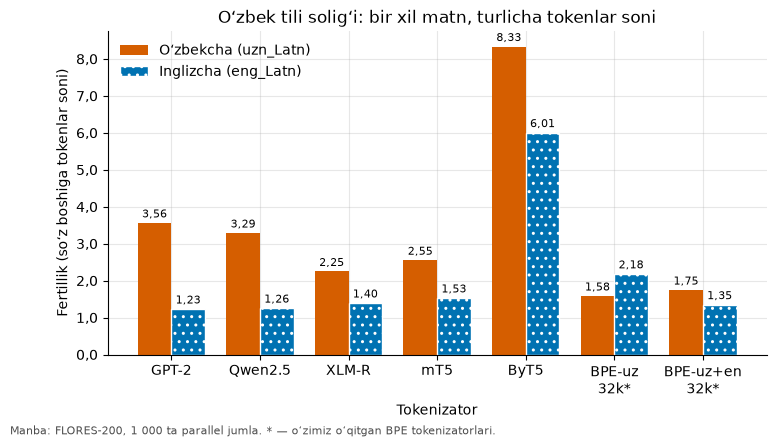

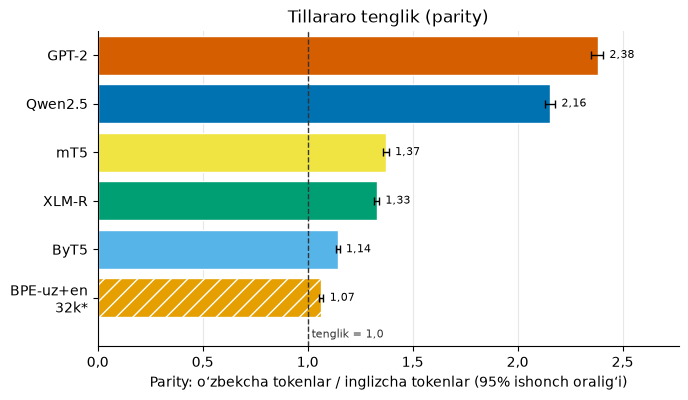

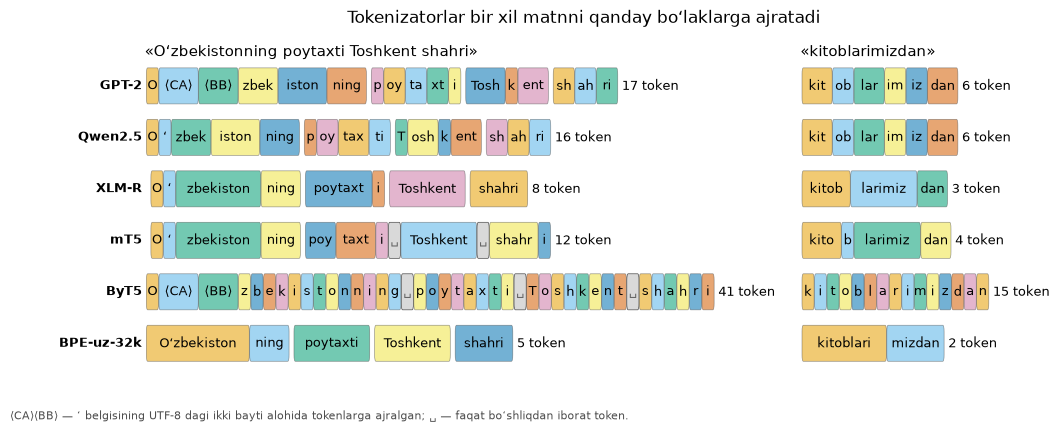

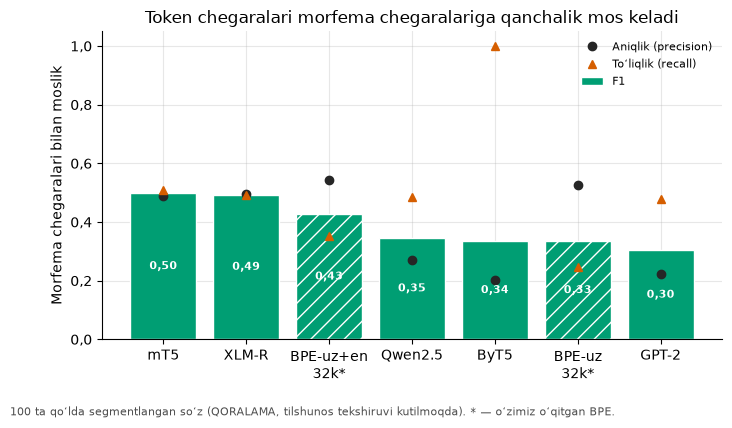

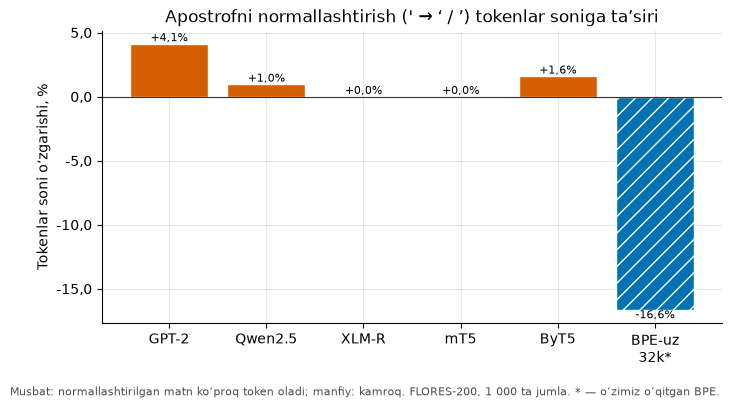

In [10]:
timer.start("6 summary")
out = ch04.results_dir()
table = pd.concat([table_pre, table_own], ignore_index=True)
rvn = pd.concat([rvn_pre, rvn_own], ignore_index=True)
kinds.update({n: "own" for n in own})
morph["kind"] = morph.tokenizer.map(kinds)

table.to_csv(out / "main_table.csv", index=False)
pd.concat([counts_pre, counts_own.drop(columns=["words_uz", "words_en"])], axis=1).to_csv(
    out / "sentence_token_counts.csv", index=False)
rvn.to_csv(out / "raw_vs_normalized.csv", index=False)
morph.to_csv(out / "morph_alignment.csv", index=False)
morph_cat.to_csv(out / "morph_alignment_by_category.csv", index=False)
morph_ex.to_csv(out / "morph_examples.csv", index=False)
pd.DataFrame(tok_info).T.rename_axis("tokenizer").to_csv(out / "tokenizers.csv")

big = max(BPE_VOCAB_SIZES) // 1000
show = [*adapters, f"BPE-uz-{big}k"] + ([f"BPE-uz+en-{big}k"] if TRAIN_BALANCED_UZ_EN else [])
fig_table = table.set_index("tokenizer").loc[show].reset_index()
figs = {
    "fig_fertility_uz_en": ch04.plot_fertility(fig_table),
    "fig_parity": ch04.plot_parity(fig_table[fig_table.tokenizer != f"BPE-uz-{big}k"]),
    "fig_token_split_example": ch04.plot_token_split(
        {n: all_adapters[n] for n in [*adapters, f"BPE-uz-{big}k"]},
        ch04.EXAMPLE_SENTENCE, ch04.EXAMPLE_WORD),
    "fig_morph_alignment": ch04.plot_morph(morph.set_index("tokenizer").loc[show].reset_index()),
    "fig_raw_vs_normalized": ch04.plot_raw_vs_normalized(
        rvn.set_index("tokenizer").loc[[*adapters, f"BPE-uz-{big}k"]].reset_index(), kinds),
}
for name, fig in figs.items():
    ch04.save_fig(fig, name)
print("Saved:", sorted(p.name for p in out.glob("fig_*")))

In [11]:
summary_cols = ["tokenizer", "kind", "vocab_size", "fertility_uz", "fertility_en", "parity",
                "parity_ci_low", "parity_ci_high", "parity_median", "continued_word_rate_uz",
                "bytes_per_token_uz", f"context_words_uz_{CONTEXT_WINDOW}"]
summary = table[summary_cols].merge(morph[["tokenizer", "f1"]].rename(columns={"f1": "morph_f1"}),
                                    on="tokenizer")
summary.to_csv(out / "summary_table.csv", index=False)
display(summary)

obs = ch04.observations(table, rvn, morph, own_names=list(own))
display(Markdown("\n".join(f"- {u}  \n  *{e}*" for u, e in obs)))
timer.stop()

,tokenizer,kind,vocab_size,fertility_uz,fertility_en,parity,parity_ci_low,parity_ci_high,parity_median,continued_word_rate_uz,bytes_per_token_uz,context_words_uz_4096,morph_f1
0,GPT-2,pretrained,50257,3.561,1.232,2.381,2.351,2.408,2.385,0.899,2.340,1150.171,0.303
1,Qwen2.5,pretrained,151665,3.289,1.257,2.156,2.129,2.179,2.161,0.892,2.534,1245.460,0.347
2,XLM-R,pretrained,250002,2.248,1.395,1.328,1.314,1.340,1.320,0.623,3.707,1821.744,0.494
3,mT5,pretrained,250100,2.553,1.532,1.373,1.358,1.386,1.365,0.769,3.264,1604.342,0.498
4,ByT5,pretrained,384,8.334,6.006,1.144,1.134,1.152,1.136,0.993,1.000,491.483,0.335
5,BPE-uz-8k,own,8000,2.023,2.582,0.646,0.639,0.653,0.644,0.496,4.119,2024.618,0.495
6,BPE-uz-16k,own,16000,1.779,2.376,0.617,0.610,0.623,0.617,0.387,4.686,2302.936,0.426
7,BPE-uz-32k,own,32000,1.585,2.184,0.598,0.592,0.604,0.597,0.286,5.258,2584.328,0.335
8,BPE-uz+en-32k,own,32000,1.745,1.350,1.065,1.054,1.075,1.067,0.380,4.775,2346.643,0.427


- Eng katta „soliq“ GPT-2 tokenizatorida: oʻzbekcha matn inglizcha tarjimasidan 2,38 baravar koʻp token oladi (95% ishonch oraligʻi 2,35–2,41).  
  *The largest tax is in GPT-2: Uzbek needs 2.38x the tokens of the English translation (95% CI 2.35-2.41).*
- Eng kichik farq ByT5 tokenizatorida: parity 1,14.  
  *The smallest gap is in ByT5: parity 1.14.*
- GPT-2 bilan 4096 tokenli kontekstga taxminan 1 150 ta oʻzbekcha soʻz sigʻadi, inglizcha esa 3 323 ta.  
  *With GPT-2, a 4096-token window holds about 1,150 Uzbek words vs 3,323 English words.*
- ByT5 oʻzbekcha soʻzlarning 99 foizini bir nechta tokenga boʻladi (inglizchada 98 foiz).  
  *ByT5 splits 99% of Uzbek words into several tokens (98% for English).*
- Apostrofni normallashtirish GPT-2 da tokenlar sonini 4,1% ga oshadi.  
  *Normalizing apostrophes changes the GPT-2 token count by +4.1%.*
- Morfema chegaralariga eng mos tokenizator — mT5 (F1 0,50), eng kam mosi — GPT-2 (F1 0,30); natijalar qoralama oltin toʻplamga asoslangan.  
  *Best morphological alignment: mT5 (F1 0.50); worst: GPT-2 (F1 0.30) -- on the DRAFT gold set.*
- Oʻzimiz oʻqitgan BPE-uz-32k oʻzbekcha fertilligi 1,58; eng yaxshi tayyor tokenizatorda 2,25.  
  *Our own BPE-uz-32k reaches Uzbek fertility 1.58; the best pretrained tokenizer reaches 2.25.*

In [12]:
runtime = timer.save(out / "runtime.json", n_sentences=N_SENTENCES,
                     n_wiki_articles=N_WIKI_ARTICLES, platform=sys.platform,
                     python=sys.version.split()[0], cpu_count=os.cpu_count())
print(f"Total runtime: {runtime['total_seconds'] / 60:.1f} min")
print(runtime["steps_seconds"])

Total runtime: 2.0 min
{'0 setup': 0.1, '1 data': 4.9, '2 tokenizers': 27.6, '3 audit': 10.4, '4a wikipedia': 35.9, '4b train BPE': 29.4, '4c audit own': 6.3, '5 morphology': 0.1, '6 summary': 3.5}


## 7. Mustaqil ish uchun topshiriqlar

1. **Yangi tokenizator qoʻshing.** Hugging Faceʼdan yana bitta ochiq tokenizatorni tanlang (masalan, `bigscience/bloom-560m` yoki `facebook/nllb-200-distilled-600M`), uni `uzling.tokenizer_stats.TokenizerAdapter` bilan oʻrab, `ch04.audit` ga qoʻshing. U jadvalning qayeriga tushdi? Nima uchun?
2. **Oltin toʻplamni kengaytiring.** `morph_gold_uz.tsv` ga oʻzingiz 20 ta soʻz qoʻshing (kamida 5 tasi feʼl, 5 tasi „qiyin“ holat: oʻzak ichida qoʻshimchaga oʻxshash qism, tovush oʻzgarishi). Natijalar qanday oʻzgardi?
3. **Turkiy tillar uchun parity.** `ch04.load_flores(("kaz_Cyrl", "eng_Latn"))` bilan qozoq tilini yuklang va parityʼni hisoblang; keyin `kir_Cyrl`, `tur_Latn`, `azj_Latn` uchun ham. Oʻzbek tili bu qatorda qayerda? Yozuv (kirill/lotin) natijaga taʼsir qiladimi?

*English note: (1) add a tokenizer, (2) add 20 gold words, (3) compute parity for other Turkic languages in FLORES-200 (kaz_Cyrl, kir_Cyrl, tur_Latn, azj_Latn). Note that `normalize_uz` is for Uzbek only; do not apply it to the other languages.*